# 09 — Figure 3: Δω500 and ΔF_net maps

Shading: Δω500 = run − control (Pa/s; blue = anomalous ascent, red =
anomalous descent). Contours: ΔF_net (W/m², solid = positive, dashed =
negative). FULL (top), UNIFORM (middle), PATTERN (bottom); 1983 El Niño
(left), 1989 La Niña (right). Both fields are computed here from the merged
model output, regridded to 1° for plotting.

Drawn at printed width (7 in). Output: `figures/fig3_omega_Fnet.png` / `.pdf`.

In [1]:
import sys
sys.path.insert(0, "../src")
import config as cfg

import os
import numpy as np
import xarray as xr
import xesmf as xe
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

plt.rcParams.update({
    "font.size": 8, "font.family": "sans-serif",
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
FIG_WIDTH = 7.0   # inches, full page width in print

EL_NINO_YEAR = 1983
LA_NINA_YEAR = 1989
RUNS = ["FULL", "UNIFORM", "PATTERN"]

## Step 1 — regrid and load Δω500 and ΔF_net

In [2]:
def event_dir(event_type):
    return cfg.ECHAM_OUTPUT_ELNINO_DIR if event_type == "El Niño" else cfg.ECHAM_OUTPUT_LANINA_DIR


def regrid_to_1deg(field):
    target = xr.Dataset({"lat": (["lat"], np.arange(-90, 91, 1.0)), "lon": (["lon"], np.arange(0, 360, 1.0))})
    regridder = xe.Regridder(field, target, "bilinear", periodic=True)
    return regridder(field)


def select_period(ds, period):
    return ds if period is None else ds.sel(time=slice(*period))


def omega500_map(atm_path, period=None):
    omega = xr.open_dataset(atm_path)["omega"]
    scale = 100.0 if omega.attrs.get("units") in ["hPa/s", "hPa s-1"] else 1.0   # read units before averaging
    omega500 = scale * select_period(omega, period).mean("time").sel(plev=50000, method="nearest")
    return regrid_to_1deg(omega500)


def fnet_map(bot_path, period=None):
    """F_net = TOA net down − surface net down (same definition as 05), W/m2."""
    ds = select_period(xr.open_dataset(bot_path), period)
    ds = regrid_to_1deg(ds[["srad0", "trad0", "srads", "trads", "ahfs", "ahfl"]].mean("time"))
    return ds["srad0"] + ds["trad0"] - ds["srads"] - ds["trads"] - ds["ahfs"] - ds["ahfl"]


omega_clim = omega500_map(cfg.CLIMATOLOGY_ATM_PATH, period=cfg.CLIM_PERIOD)
fnet_clim = fnet_map(cfg.CLIMATOLOGY_BOT_PATH, period=cfg.CLIM_PERIOD)

delta_omega, delta_fnet = {}, {}
for year, event_type in [(EL_NINO_YEAR, "El Niño"), (LA_NINA_YEAR, "La Niña")]:
    for run in RUNS:
        atm_path = os.path.join(event_dir(event_type), f"{year}_{run}_echam6_ATM_mm_1976-1999.nc")
        bot_path = os.path.join(event_dir(event_type), f"{year}_{run}_echam6_BOT_mm_1976-1999.nc")
        if not (os.path.exists(atm_path) and os.path.exists(bot_path)):
            print(f"missing file(s) for {year} {run} -- skipping")
            continue
        delta_omega[(year, run)] = omega500_map(atm_path) - omega_clim
        delta_fnet[(year, run)] = fnet_map(bot_path) - fnet_clim
        print(f"loaded {year} {run}")

loaded 1983 FULL
loaded 1983 UNIFORM
loaded 1983 PATTERN
loaded 1989 FULL
loaded 1989 UNIFORM
loaded 1989 PATTERN


## Step 2 — draw the 3 × 2 grid

Colours follow the caption: in the `RdBu_r` shading negative Δω500 (ascent)
is blue and positive (descent) red, and the ΔF_net contours use the same
sign–colour convention (red positive, blue negative).

ΔF_net contours at ±10, 20, 30, 40, 50 W m-2  (state this in the caption)
saved figures/fig3_omega_Fnet.png
saved figures/fig3_omega_Fnet.pdf


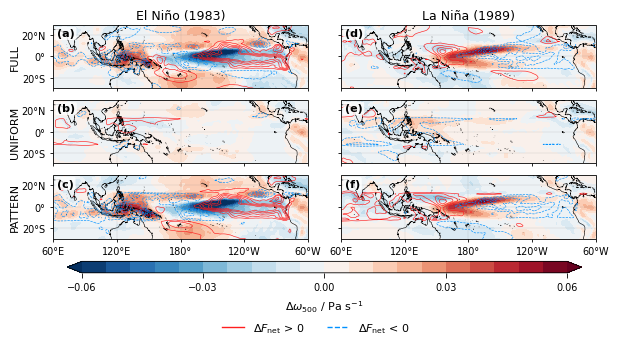

In [3]:
row_names = RUNS
columns = [(EL_NINO_YEAR, "El Niño"), (LA_NINA_YEAR, "La Niña")]
panel_letters = [["a", "d"], ["b", "e"], ["c", "f"]]

VMIN, VMAX = -0.06, 0.06
N_LEVELS = 21     # shading boundaries (20 bands)
N_TICKS = 5       # colour bar labels: -0.06, -0.03, 0, 0.03, 0.06
levels = np.linspace(VMIN, VMAX, N_LEVELS)
cbar_ticks = np.linspace(VMIN, VMAX, N_TICKS)

FNET_CONTOUR_LEVELS = np.array([10, 20, 30, 40, 50])   # W/m2, drawn for both signs
FNET_POS_COLOR = "#FF1F1F"       # ΔF_net > 0, solid (bright red)
FNET_NEG_COLOR = "#0091FF"       # ΔF_net < 0, dashed (bright blue)
FNET_CONTOUR_ALPHA = 1.0
FNET_LINEWIDTH = 0.45   # thin lines; the original design used 0.6
SHOW_LON_LABELS = True   # <- False hides the longitude labels and meridians
LON_WEST, LON_EAST = 60, 300   # map extent: 60°E to 60°W
LON_TICKS = [60, 120, 180, 240, 300]   # 60°E, 120°E, 180°, 120°W, 60°W
LAT_TICKS = [-20, 0, 20]     # ±30° would collide between the tightly stacked rows

fig, axes = plt.subplots(3, 2, figsize=(FIG_WIDTH, 3.3),
                         subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)},
                         gridspec_kw={"wspace": 0.13, "hspace": 0.08})

mesh = None
for col, (year, event_type) in enumerate(columns):
    axes[0, col].set_title(f"{event_type} ({year})", fontsize=9, pad=4)
    for row, run in enumerate(row_names):
        ax = axes[row, col]
        ax.set_autoscale_on(False)
        ax.set_extent([LON_WEST, LON_EAST, -30, 30], crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.NaturalEarthFeature("physical", "land", "50m", edgecolor="black", facecolor="none"),
                       linewidth=0.4)

        # plain axis ticks rather than gridliner labels: drawn on every frame, labelled on the outer ones
        ax.set_xticks(LON_TICKS, crs=ccrs.PlateCarree())
        ax.set_yticks(LAT_TICKS, crs=ccrs.PlateCarree())
        ax.xaxis.set_major_formatter(LongitudeFormatter())
        ax.yaxis.set_major_formatter(LatitudeFormatter())
        ax.tick_params(length=2, labelsize=7, labelleft=(col == 0),
                       labelbottom=(row == 2) and SHOW_LON_LABELS)
        ax.gridlines(draw_labels=False, xlocs=LON_TICKS if SHOW_LON_LABELS else [], ylocs=LAT_TICKS,
                     linewidth=0.2, color="gray", alpha=0.5)

        key = (year, run)
        if key in delta_omega:
            mesh = ax.contourf(delta_omega[key].lon, delta_omega[key].lat, delta_omega[key].values,
                               levels=levels, cmap="RdBu_r", extend="both", transform=ccrs.PlateCarree())
            ax.contour(delta_fnet[key].lon, delta_fnet[key].lat, delta_fnet[key].values,
                       levels=FNET_CONTOUR_LEVELS, colors=FNET_POS_COLOR, linewidths=FNET_LINEWIDTH, linestyles="solid",
                       alpha=FNET_CONTOUR_ALPHA, transform=ccrs.PlateCarree())
            ax.contour(delta_fnet[key].lon, delta_fnet[key].lat, delta_fnet[key].values,
                       levels=-FNET_CONTOUR_LEVELS[::-1], colors=FNET_NEG_COLOR, linewidths=FNET_LINEWIDTH, linestyles="dashed",
                       alpha=FNET_CONTOUR_ALPHA, transform=ccrs.PlateCarree())
        else:
            ax.text(0.5, 0.5, "missing data", transform=ax.transAxes, ha="center", va="center", fontsize=8, color="gray")

        ax.text(0.015, 0.94, f"({panel_letters[row][col]})", transform=ax.transAxes, fontsize=8, fontweight="bold",
                va="top", ha="left", bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.8))
        if col == 0:
            ax.text(-0.15, 0.5, run, transform=ax.transAxes, rotation=90, va="center", ha="center", fontsize=8)

if mesh is not None:
    cbar = fig.colorbar(mesh, ax=axes, orientation="horizontal", fraction=0.045, pad=0.09, aspect=45,
                        ticks=cbar_ticks, extendfrac=0.03)
    cbar.set_label(r"$\Delta\omega_{500}$ / Pa s$^{-1}$", fontsize=8)
    cbar.ax.tick_params(labelsize=7, width=0.6)

legend_handles = [
    Line2D([0], [0], color=FNET_POS_COLOR, linestyle="-", linewidth=1.0, label=r"$\Delta F_{\rm net}$ > 0"),
    Line2D([0], [0], color=FNET_NEG_COLOR, linestyle="--", linewidth=1.0, label=r"$\Delta F_{\rm net}$ < 0"),
]
# contour interval is given in the caption, not on the figure
print("ΔF_net contours at ±" + ", ".join(f"{v:g}" for v in FNET_CONTOUR_LEVELS) + " W m-2  (state this in the caption)")
fig.legend(handles=legend_handles, loc="upper center", ncol=2, frameon=False, fontsize=8,
           bbox_to_anchor=(0.5, -0.005))

os.makedirs(cfg.FIGURES_DIR, exist_ok=True)
for ext in ["png", "pdf"]:
    out_path = os.path.join(cfg.FIGURES_DIR, f"fig3_omega_Fnet.{ext}")
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    print("saved", os.path.relpath(out_path, cfg.REPO_ROOT))
plt.show()